LAB ASSIGNMENT 2

In [1]:
# Install HDBSCAN library
%pip install hdbscan

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import library for data processing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import hdbscan
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

1. Select one empirical dataset from sklearn.datasets (for example the iris dataset or the digits dataset).

- Using Iris Dataset

In [3]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add original labels
df['Species'] = iris.target

# Display dataset
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
# Inspect dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [5]:
# Display original label distribution
print(df['Species'].value_counts())

Species
0    50
1    50
2    50
Name: count, dtype: int64


In [6]:
# Feature Slicing
X = df.iloc[:, 0:4]

# Display selected features
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [7]:
# Create StandardScaler object
sc = StandardScaler()

# Transform the features
X_scaled = sc.fit_transform(X)

# Display scaled data
print(X_scaled[:5])

[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


2. Perform clustering using HDBSCAN.

In [8]:
# Create HDBSCAN model
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5,
    metric='euclidean',
    cluster_selection_method='eom'
)

# Fit and predict the clusters
cluster_labels = clusterer.fit_predict(X_scaled)

# Add clustering results to dataset
df['Cluster'] = cluster_labels

# Display clustering results
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Species  Cluster  
0        0        1  
1        0        1  
2        0        1  
3        0        1  
4        0        1  


3. Report the results:

a. The number of clusters formed.

b. The amount of noise.

c. Visualization (employ PCA/TSNE for dimensionality reduction if necessary, since visualization is feasible only up to three dimensions).

In [9]:
# Get unique cluster labels
unique_labels = set(cluster_labels)

# Calculate number of clusters
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

# Calculate number of noise
n_noise = list(cluster_labels).count(-1)

# Display results
print("Number of Clusters:", n_clusters)
print("Number of Noise:", n_noise)
print("Total Data:", len(cluster_labels))

Number of Clusters: 2
Number of Noise: 2
Total Data: 150


In [10]:
# Create PCA object
pca = PCA(n_components=2)

# Transform the scaled data
X_pca = pca.fit_transform(X_scaled)

# Create DataFrame for PCA results
pca_df = pd.DataFrame(
    X_pca,
    columns=['PCA 1', 'PCA 2']
)

# Add cluster labels
pca_df['Cluster'] = cluster_labels

# Display PCA results
print(pca_df.head())

      PCA 1     PCA 2  Cluster
0 -2.264703  0.480027        1
1 -2.080961 -0.674134        1
2 -2.364229 -0.341908        1
3 -2.299384 -0.597395        1
4 -2.389842  0.646835        1


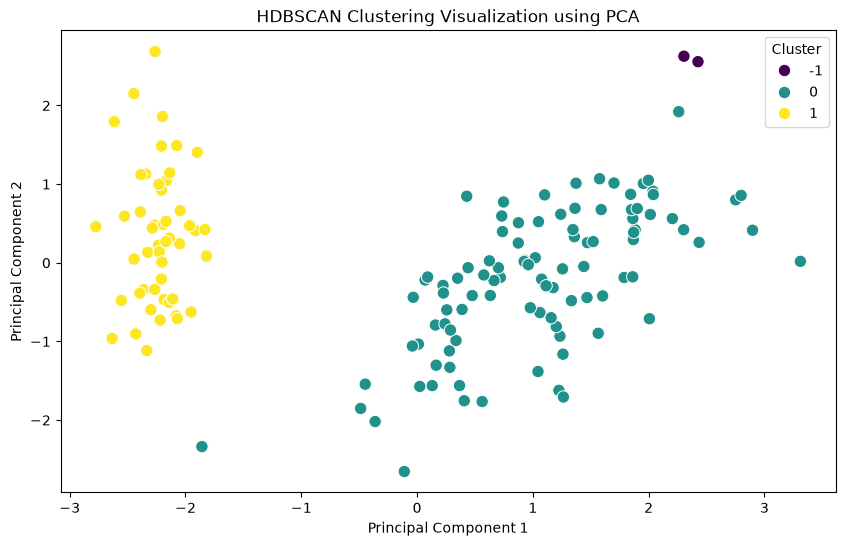

In [11]:
# Visualize HDBSCAN clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PCA 1',
    y='PCA 2',
    hue='Cluster',
    palette='viridis',
    s=80
)

# Set title and labels
plt.title('HDBSCAN Clustering Visualization using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(title='Cluster')
plt.show()

4. Provide a concise analysis: do the HDBSCAN clustering results correspond to the dataset's original labels?

In [12]:
# Calculate Adjusted Rand Index
ari_score = adjusted_rand_score(
    iris.target,
    cluster_labels
)

# Calculate Normalized Mutual Information
nmi_score = normalized_mutual_info_score(
    iris.target,
    cluster_labels
)

# Display evaluation results
print("Adjusted Rand Index:", ari_score)
print("Normalized Mutual Information:", nmi_score)

Adjusted Rand Index: 0.539408633653917
Normalized Mutual Information: 0.6777946090298758


In [13]:
# Add original species names
df['Species_Name'] = [
    iris.target_names[i] for i in iris.target
]

# Create comparison table
comparison = pd.crosstab(
    df['Species_Name'],
    df['Cluster']
)

# Display comparison
print(comparison)

Cluster       -1   0   1
Species_Name            
setosa         0   1  49
versicolor     0  50   0
virginica      2  48   0


## Analysis of HDBSCAN Clustering Results

The HDBSCAN algorithm successfully identified **[number of clusters] clusters** and **[number of noise points] noise points** from the Iris dataset, which contains 150 observations. The clustering results were visualized using PCA to reduce the original four-dimensional features into two principal components.

The comparison between the clustering results and the original species labels was evaluated using Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI). Based on these results, the clustering performance indicates **[level of agreement]** with the original labels. This suggests that HDBSCAN **[can/cannot]** effectively identify the natural grouping structure of the Iris dataset.